# ASTRA AION-ARC v2.8 — real-game validation challenger

Reuses the Tufa Labs Duck/TAAF notebook and original AION v2.5 overlays. Default profile: recovery. Existing official submission #57848621 is preserved.

Normal execution plays ls20 and vc33 with the offline local model for at most 30 minutes after setup. Competition rerun plays the gateway game list without the public-game filter. The commit-only Parquet is generated AFTER instrumented model responses and environment actions. It is never evidence of a leaderboard score.

No Kaggle run or score is claimed. All third-party code/model notices remain applicable.


# AION-ARC v2.3 — 100% target (UNVERIFIED)\n\n# Tufa Labs ARC3 submission

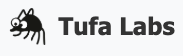

This notebook executes the ARC-AGI-3 solver written by the Tufa Labs team; in alphabetical order: Harold Bessis, Jeroen Cottaar, Isaiah Pressman, Andries Smit, Michal Tesnar, and Stefano Viel.

You will only find infrastructure and diagnostics in this notebook; the actual solver code is in an attached dataset. See our writeup on the competition forum to learn more about that the solver actually does.

It installs the ARC runtime from the competition wheelhouse, makes the bundled source
snapshot importable, runs any solver setup commands, loads the pickled benchmark, plays the
competition games, and writes results to `/kaggle/working`. Diagnostics are minimised during
a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`) and kept full otherwise. 

**Experimental transport-safe package**: byte-preserving Python execution wrapper to avoid Kaggle import indentation changes; this does not demonstrate execution, successful submission, or a hidden leaderboard score.


In [ ]:
exec(compile("import json\nimport os\nimport platform\nimport random\nimport subprocess\nimport sys\nfrom pathlib import Path\n\nif sys.version_info[:2] != (3, 12):\n    raise RuntimeError(\"Offline vLLM wheels require Python 3.12; copy the public Tufa notebook and pin its original environment\")\nTRUE_RERUN = os.environ.get(\"KAGGLE_IS_COMPETITION_RERUN\", \"\").strip().lower() in (\"1\", \"true\")\nASTRA_PROFILE = os.environ.get(\"ASTRA_PROFILE\", \"recovery\").strip().lower()\nif ASTRA_PROFILE not in (\"upstream\", \"recovery\"):\n    raise ValueError(\"ASTRA_PROFILE must be upstream or recovery\")\nASTRA_PUBLIC_GAMES = (\"ls20\", \"vc33\")\nASTRA_PUBLIC_BUDGET_S = 1800\nrandom.seed(0)\n\n# Fail before the expensive offline install if inputs/hardware are missing.\nASTRA_COMPETITION_ROOT = Path(\"/kaggle/input/competitions/arc-prize-2026-arc-agi-3\")\nif not (ASTRA_COMPETITION_ROOT / \"arc_agi_3_wheels\").is_dir():\n    candidates = sorted(Path(\"/kaggle/input\").rglob(\"arc_agi_3_wheels\"))\n    if len(candidates) != 1:\n        raise RuntimeError(\"Competition wheelhouse missing or ambiguous\")\n    ASTRA_COMPETITION_ROOT = candidates[0].parent\nif not TRUE_RERUN and not (ASTRA_COMPETITION_ROOT / \"environment_files\").is_dir():\n    raise RuntimeError(\"Public environment files are not attached\")\nfor ref in ['jeroencottaar/taaf-kaggle-source-share', 'driessmit1/arc3-vllm-h100-wheelhouse-v3', 'driessmit1/vrfai-qwen3-6-27b-fp8-hf-snapshot']:\n    owner, slug = ref.split(\"/\", 1)\n    paths = [Path(\"/kaggle/input\") / slug, Path(\"/kaggle/input/datasets\") / owner / slug]\n    if not any(p.is_dir() for p in paths):\n        raise RuntimeError(\"Missing attached dataset: \" + ref)\ngpu = subprocess.check_output([\n    \"nvidia-smi\", \"--query-gpu=name,memory.total\", \"--format=csv,noheader,nounits\"\n], text=True, timeout=15).strip().splitlines()\nif len(gpu) != 1 or not any(s in gpu[0].lower() for s in (\"rtx pro 6000\", \"h100\")):\n    raise RuntimeError(\"Duck FP8 setup requires one RTX PRO 6000 or H100; found \" + repr(gpu))\nos.environ[\"KAGGLE_GPU_TYPE\"] = \"h100\" if \"h100\" in gpu[0].lower() else \"rtx-pro-6000\"\nos.environ[\"KAGGLE_GPU_COUNT\"] = \"1\"\nos.environ[\"HF_HUB_OFFLINE\"] = \"1\"\nos.environ[\"TRANSFORMERS_OFFLINE\"] = \"1\"\nwork = Path(\"/kaggle/working\")\nwork.mkdir(parents=True, exist_ok=True)\n# Prevent a stale demo artifact from masquerading as a new successful run.\nfor stale in (\"submission.parquet\", \"astra_gameplay.jsonl\", \"astra_runtime_evidence.json\"):\n    (work / stale).unlink(missing_ok=True)\nprint(\"ASTRA_V28_RUNTIME\", json.dumps({\n    \"mode\": \"HIDDEN_RERUN\" if TRUE_RERUN else \"REAL_PUBLIC_GAMES\",\n    \"profile\": ASTRA_PROFILE, \"gpu\": gpu, \"python\": platform.python_version(),\n    \"official_score\": \"UNVERIFIED\", \"preserved_submission\": 57848621,\n}), flush=True)\n", 'astra-v28-runtime', "exec"), globals())


In [ ]:
exec(compile("import json\nimport os\nimport pickle\nimport subprocess\nimport sys\nimport sysconfig\nimport time\nfrom datetime import datetime, timedelta\nfrom pathlib import Path\nfrom urllib.request import urlopen\n\n# True only inside a real competition rerun; switches diagnostics + soft deadline.\nTRUE_SUBMISSION = os.environ.get(\"KAGGLE_IS_COMPETITION_RERUN\", \"\").strip().lower() in {\"1\", \"true\"}\nNOTEBOOK_START_EPOCH = time.time()\n\n# Non-interactive matplotlib backend: diagnostics render plots with no display attached.\nos.environ[\"MPLBACKEND\"] = \"Agg\"\n# Marks the run as a (real or emulated) submission so the framework + solver can adjust.\nos.environ[\"TAAF_RUN_AS_SUBMISSION\"] = \"1\" if TRUE_SUBMISSION else \"0\"\n# In submission, disable the periodic JSON/HTML diagnostics writes and per-frame logging.\nos.environ[\"TAAF_MINIMAL_DIAGNOSTICS\"] = \"1\" if TRUE_SUBMISSION else \"0\"\n# Pin arc_agi's cached level_reset_only before its client is built (RESET keeps the level).\nos.environ[\"ONLY_RESET_LEVELS\"] = \"true\"\n\n# Prepend the CUDA toolkit to the linker path (it is off it on Kaggle GPU images) so the\n# solver's GPU libraries (e.g. vllm / torch) can link against libcuda.\ncuda_library_path = \"/usr/local/nvidia/lib64\"\nos.environ[\"LIBRARY_PATH\"] = os.pathsep.join(\n    entry for entry in [cuda_library_path, *os.environ.get(\"LIBRARY_PATH\", \"\").split(os.pathsep)] if entry\n)\n\n# Everything the run produces is written here.\nWORKING_DIR = Path(\"/kaggle/working\")\nWORKING_DIR.mkdir(parents=True, exist_ok=True)\nprint(f\"taaf.kaggle: TRUE_SUBMISSION={TRUE_SUBMISSION}\")", 'astra-v28-original-2', "exec"), globals())


In [ ]:
exec(compile("# Install the ARC runtime from the bundled competition wheels.\n# Quiet: stdout is discarded; stderr (and a non-zero exit) still surface real failures.\nsubprocess.check_call(\n    [\n        sys.executable,\n        \"-m\",\n        \"pip\",\n        \"install\",\n        \"--quiet\",\n        \"--no-index\",\n        \"--no-warn-conflicts\",\n        \"--disable-pip-version-check\",\n        \"--find-links\",\n        str(ASTRA_COMPETITION_ROOT / \"arc_agi_3_wheels\"),\n        \"arc-agi\",\n    ],\n    stdout=subprocess.DEVNULL,\n)", 'astra-v28-original-4', "exec"), globals())


In [ ]:
exec(compile("# Kaggle inputs attached to this notebook, plus bookkeeping paths used below.\nDATASET_SOURCES = [\"jeroencottaar/taaf-kaggle-source-share\", \"driessmit1/arc3-vllm-h100-wheelhouse-v3\", \"driessmit1/vrfai-qwen3-6-27b-fp8-hf-snapshot\"]\nKERNEL_SOURCES = []\nDATASET_BUNDLE_MARKER = \"taaf-kaggle-bundle.json\"\nSETUP_ENV_PATH = WORKING_DIR / \"taaf_setup_env.json\"\n\n\n# Locate the source dataset by its marker file rather than a fixed mount path.\ndef _find_bundle_dir() -> Path:\n    for marker in Path(\"/kaggle/input\").rglob(DATASET_BUNDLE_MARKER):\n        return marker.parent\n    raise RuntimeError(\"TAAF source bundle not found under /kaggle/input.\")\n\n\n# Kaggle mounts a dataset at /kaggle/input/<slug> or /kaggle/input/datasets/<owner>/<slug>\n# (depending on owner / slug collisions), so probe both and use whichever exists. Utility\n# scripts mount under /kaggle/usr/lib/notebooks/<owner>/<slug>.\ndef _dataset_mount_candidates(ref: str) -> list[Path]: return [Path(\"/kaggle/input\") / ref.split(\"/\", 1)[1], Path(\"/kaggle/input/datasets\") / ref.split(\"/\", 1)[0] / ref.split(\"/\", 1)[1]]\n\n\ndef _kernel_mount_candidates(ref: str) -> list[Path]: return [Path(\"/kaggle/usr/lib/notebooks\") / ref.split(\"/\", 1)[0] / ref.split(\"/\", 1)[1]]\n\n\ndef _first_existing(candidates: list[Path]) -> Path | None: return next((c for c in candidates if c.exists()), None)\n\n\nBUNDLE_DIR = _find_bundle_dir()\nprint(f\"taaf.kaggle: source bundle = {BUNDLE_DIR}\")\n\n# Map each attached input to where Kaggle actually mounted it (the source bundle is index 0).\nkaggle_input_paths: dict[str, str] = {}\nfor i, ref in enumerate(DATASET_SOURCES):\n    candidates = _dataset_mount_candidates(ref)\n    resolved = BUNDLE_DIR if i == 0 else _first_existing(candidates)\n    kaggle_input_paths[ref] = str(resolved or candidates[0])\nfor ref in KERNEL_SOURCES:\n    candidates = _kernel_mount_candidates(ref)\n    kaggle_input_paths[ref] = str(_first_existing(candidates) or candidates[0])\n\n# Published to setup commands and the solver via the environment:\nsetup_env = {\n    # JSON {ref: mount_path} so they can locate every attached dataset / utility script.\n    \"TAAF_KAGGLE_INPUT_PATHS\": json.dumps(kaggle_input_paths, sort_keys=True),\n    # The attached dataset refs in order (index 0 is this source bundle).\n    \"TAAF_KAGGLE_DATASET_SOURCES\": json.dumps(DATASET_SOURCES),\n    # The attached utility-script / kernel refs.\n    \"TAAF_KAGGLE_KERNEL_SOURCES\": json.dumps(KERNEL_SOURCES),\n}\nos.environ.update(setup_env)\nSETUP_ENV_PATH.write_text(json.dumps(setup_env, indent=2, sort_keys=True) + \"\\n\")\nprint(f\"taaf.kaggle: input paths = {setup_env['TAAF_KAGGLE_INPUT_PATHS']}\")", 'astra-v28-original-6', "exec"), globals())


In [ ]:
exec(compile("# Each bundled repo exposes its importable tree at <repo>/src or <repo>.\ndef _source_path_entries(bundle_dir: Path) -> list:\n    entries = []\n    for repo in sorted((bundle_dir / \"src\").iterdir(), reverse=True):\n        for candidate in (repo / \"src\", repo):\n            if candidate.is_dir():\n                entries.append(candidate)\n    return entries\n\n\n# Environment handed to each setup command (paths + any keys it has persisted).\ndef _command_env() -> dict:\n    env = os.environ.copy()\n    # \"$PYTHON\" in a command resolves to this notebook's interpreter.\n    env[\"PYTHON\"] = sys.executable\n    # Absolute path to the mounted source bundle.\n    env[\"TAAF_KAGGLE_BUNDLE_DIR\"] = str(BUNDLE_DIR)\n    # The writable /kaggle/working directory.\n    env[\"TAAF_KAGGLE_WORKING_DIR\"] = str(WORKING_DIR)\n    # A command writes a JSON object here to persist env keys to later commands + the run.\n    env[\"TAAF_KAGGLE_SETUP_ENV\"] = str(SETUP_ENV_PATH)\n    env.update({str(k): str(v) for k, v in json.loads(SETUP_ENV_PATH.read_text()).items()})\n    return env\n\n\n# Make the bundled repos importable here (sys.path) and in child processes (.pth).\nsource_entries = _source_path_entries(BUNDLE_DIR)\nfor entry in source_entries:\n    sys.path.insert(0, str(entry))\npth_path = Path(sysconfig.get_paths()[\"purelib\"]) / \"taaf_kaggle_sources.pth\"\npth_path.write_text(\"\".join(f\"{entry}\\n\" for entry in source_entries))\nprint(f\"taaf.kaggle: wrote {pth_path} ({len(source_entries)} source roots)\")\n\n# Solver setup commands (wheels, vLLM server startup, ...) run before the benchmark loads.\nenv = _command_env()\nfor command in json.loads((BUNDLE_DIR / \"setup_commands.json\").read_text()):\n    print(f\"taaf.kaggle: setup command: {command}\", flush=True)\n    subprocess.run(command, shell=True, check=True, cwd=WORKING_DIR, env=env)\n    # Re-read in case the command persisted new env keys.\n    env = _command_env()\n    os.environ.update(env)\n\n# Honour any PYTHONPATH a setup command exported.\nfor entry in reversed([e for e in os.environ.get(\"PYTHONPATH\", \"\").split(os.pathsep) if e]):\n    if entry not in sys.path:\n        sys.path.insert(0, entry)", 'astra-v28-original-8', "exec"), globals())


In [ ]:
exec(compile("# AION-ARC v2.1 — TARDIGRADE / evidence / prediction execution overlay\nimport shutil\nimport sys\nfrom pathlib import Path\n\nAION_SENTINEL = \"AION_VERIFICATION_ADDENDUM\"\nAION_SANDBOX_SENTINEL = 'AION_GUARD_VERSION = \"2.1\"'\noverlay_root = WORKING_DIR / \"aion_arc_v21_overlay\"\nif overlay_root.exists():\n    shutil.rmtree(overlay_root)\n\ntool_candidates = sorted((BUNDLE_DIR / \"src\").rglob(\"inference/agent/tool_agent.py\"))\nif not tool_candidates:\n    raise RuntimeError(\"AION v2.1: Duck tool_agent.py not found.\")\ntool_src = tool_candidates[0]\nimport_root = next((p for p in tool_src.parents if (p / \"inference\").is_dir()), None)\nif import_root is None:\n    raise RuntimeError(\"AION v2.1: could not resolve Duck import root.\")\n\nshutil.copytree(import_root, overlay_root)\nprompts_path = overlay_root / \"inference\" / \"agent\" / \"prompts.py\"\ntool_path = overlay_root / \"inference\" / \"agent\" / \"tool_agent.py\"\nsandbox_path = overlay_root / \"inference\" / \"agent\" / \"python_tool_sandbox.py\"\n\naddendum = r'''\nAION_VERIFICATION_ADDENDUM = (\n    \"\\n\\nAION-ARC v2.1 / ASTRA evidence protocol:\\n\"\n    \"- MYTHOS ASTRA Ω: evidence first -> act -> adversarial audit -> correction -> verification². Never infer PASS from a plausible-looking board.\\n\"\n    \"- BRICK PROOF GATE Ω: every claimed mechanic needs an observable success criterion and a falsifier. Maintain CONFIRMED/CANDIDATE/UNKNOWN, not vibes.\\n\"\n    \"- NO-REPEAT Ω: call aion_plan_audit(...) before acting. A repeated gameplay-inert probe requires an explicit new reason; do not burn actions by looping.\\n\"\n    \"- TARDIGRADE Ω: use checkpoints conceptually. For risky reversible probes, add rollback_on_mismatch=True; the runtime will attempt ACTION7 and verify whether the gameplay signature returned to the checkpoint.\\n\"\n    \"- Outcome learning: use aion_evidence(transitions) to learn from BOTH successful and failed actions. Preserve cross-level rules only when evidence survives new levels.\\n\"\n    \"- Retrodict before live probing. Use compact gameplay signatures that ignore likely edge HUD/timer strips.\\n\"\n    \"- Every multi-action plan should carry machine-checkable expectations where possible: expect_change, expect_level_completed, expect_reward_min, expect_valid_actions_contains, or expect_level.\\n\"\n    \"- The patched action(actions) executes batches one action at a time and aborts the remaining plan on the first prediction mismatch or terminal transition.\\n\"\n    \"- If a mismatch occurs and rollback_on_mismatch=True, ACTION7 is attempted only when available; aion_rollback_verified reports whether the gameplay signature returned exactly to the pre-action checkpoint.\\n\"\n    \"- Use hypothesis tournaments: keep multiple candidate mechanics alive when evidence is ambiguous, score them against recorded transitions, and spend a live action only when history cannot discriminate.\\n\"\n    \"- After ~20 non-progress actions on one level, stop broad probing. Build a compact executable transition model, verify it retrodicts known transitions, then do bounded BFS/DFS/beam search.\\n\"\n    \"- ZERO-COST/LOCAL-FIRST: no external API or Internet assumption; all reasoning must work inside the Kaggle offline runtime.\\n\"\n    \"\\nAION sandbox helpers available in python:\\n\"\n    \"- aion_frame_signature(frame): HUD-resistant gameplay signature.\\n\"\n    \"- aion_evidence(transitions, limit=12): compact success/failure ledger.\\n\"\n    \"- aion_plan_audit(plan, valid_actions, transitions, last_action_result): warnings before execution.\\n\"\n    \"- aion_information_gain(actions, hypotheses, state): entropy-ranked experiments that maximally separate competing world models.\\n\"\n    \"- aion_choose_probe(actions, hypotheses, state, risk=None): choose the most informative low-risk live probe when history cannot discriminate.\\n\"\n    \"- action([...]) supports per-step metadata: expect_change, expect_level_completed, expect_reward_min, expect_valid_actions_contains, expect_level, rollback_on_mismatch, force_probe, hypothesis.\\n\"\n)\n'''\n\nptext = prompts_path.read_text()\nif AION_SENTINEL not in ptext:\n    prompts_path.write_text(ptext.rstrip() + \"\\n\\n\" + addendum.lstrip())\n\nttext = tool_path.read_text()\nif \"AION_VERIFICATION_ADDENDUM,\" not in ttext:\n    anchor = \"    VISUAL_GAME_ADDENDUM,\\n)\"\n    if anchor not in ttext:\n        raise RuntimeError(\"AION v2.1: prompt import anchor changed.\")\n    ttext = ttext.replace(anchor, \"    VISUAL_GAME_ADDENDUM,\\n    AION_VERIFICATION_ADDENDUM,\\n)\", 1)\nif \"prompt += AION_VERIFICATION_ADDENDUM\" not in ttext:\n    anchor = \"    prompt += PYTHON_ADDENDUM\\n\"\n    if anchor not in ttext:\n        raise RuntimeError(\"AION v2.1: system-prompt anchor changed.\")\n    ttext = ttext.replace(anchor, anchor + \"    prompt += AION_VERIFICATION_ADDENDUM\\n\", 1)\ntool_path.write_text(ttext)\n\nstext = sandbox_path.read_text()\nif AION_SANDBOX_SENTINEL not in stext:\n    guard = r'''    AION_GUARD_VERSION = \"2.1\"\n    \n    def _aion_bbox(boundary):\n        pts = list(boundary or [])\n        if not pts:\n            return None\n        rows = [int(p[0]) for p in pts]\n        cols = [int(p[1]) for p in pts]\n        return (min(rows), min(cols), max(rows), max(cols))\n    \n    def aion_probable_hud(node, shape):\n        rows, cols = tuple(shape or (0, 0))\n        bbox = _aion_bbox(node.get(\"boundary\", []))\n        if not bbox or rows <= 0 or cols <= 0:\n            return False\n        r0, c0, r1, c1 = bbox\n        height = r1 - r0 + 1\n        width = c1 - c0 + 1\n        touches_edge = r0 == 0 or c0 == 0 or r1 == rows - 1 or c1 == cols - 1\n        long_edge_strip = (width >= max(8, int(cols * 0.75)) and height <= 3) or (height >= max(8, int(rows * 0.75)) and width <= 3)\n        return bool(touches_edge and long_edge_strip)\n    \n    def aion_frame_signature(frame):\n        if frame is None:\n            return ()\n        seg = getattr(frame, \"segmentation\", {}) or {}\n        shape = getattr(frame, \"shape\", (0, 0))\n        nodes = []\n        for node in seg.get(\"nodes\", []):\n            if aion_probable_hud(node, shape):\n                continue\n            bbox = _aion_bbox(node.get(\"boundary\", []))\n            dims = None if bbox is None else (bbox[2] - bbox[0] + 1, bbox[3] - bbox[1] + 1)\n            nodes.append((\n                str(node.get(\"color\", \"\")),\n                str(node.get(\"hash\", \"\")),\n                int(node.get(\"pixels\", 0) or 0),\n                dims,\n                len(node.get(\"children\", []) or []),\n            ))\n        return tuple(sorted(nodes))\n    \n    def aion_evidence(transitions, limit=12):\n        rows = []\n        for tr in list(transitions or [])[-max(1, int(limit)):]:\n            before = aion_frame_signature(getattr(tr, \"before_frame\", None))\n            after = aion_frame_signature(getattr(tr, \"after_frame\", None))\n            result = getattr(tr, \"result\", {}) or {}\n            rows.append({\n                \"action\": str(getattr(tr, \"action\", \"\")),\n                \"gameplay_changed\": before != after,\n                \"board_changed\": bool(result.get(\"board_changed\", False)),\n                \"level_completed\": bool(result.get(\"level_completed\", False)),\n                \"game_over\": bool(result.get(\"game_over\", False)),\n                \"reward\": result.get(\"reward\"),\n            })\n        return rows\n    \n    def aion_plan_audit(plan, valid_actions, transitions=None, last_action_result=None):\n        valid = {str(x).upper() for x in (valid_actions or [])}\n        warnings = []\n        plan = list(plan or [])\n        for i, item in enumerate(plan):\n            spec = {\"action\": item} if isinstance(item, str) else dict(item or {})\n            action_name = str(spec.get(\"action\", \"\")).upper()\n            if not action_name:\n                warnings.append(f\"step {i+1}: missing action\")\n                continue\n            if valid and action_name not in valid:\n                warnings.append(f\"step {i+1}: {action_name} not currently valid\")\n            if action_name == \"RESET\" and \"ACTION7\" in valid:\n                warnings.append(f\"step {i+1}: RESET while ACTION7 is available\")\n        ev = aion_evidence(transitions or [], limit=3)\n        if plan and ev:\n            first = plan[0] if isinstance(plan[0], str) else str((plan[0] or {}).get(\"action\", \"\"))\n            last = ev[-1]\n            if str(first).upper() == str(last.get(\"action\", \"\")).upper() and not last.get(\"gameplay_changed\") and not bool(last.get(\"level_completed\")):\n                warnings.append(\"first action repeats the latest gameplay-inert probe; justify with force_probe\")\n        return warnings\n    \n    def aion_expectation_mismatches(spec, action_result, frame):\n        spec = dict(spec or {})\n        result = dict(action_result or {})\n        mismatches = []\n        if \"expect_change\" in spec:\n            actual = bool(result.get(\"board_changed\", False))\n            if actual != bool(spec.get(\"expect_change\")):\n                mismatches.append(f\"expect_change={bool(spec.get('expect_change'))} actual={actual}\")\n        if \"expect_level_completed\" in spec:\n            actual = bool(result.get(\"level_completed\", False))\n            if actual != bool(spec.get(\"expect_level_completed\")):\n                mismatches.append(f\"expect_level_completed={bool(spec.get('expect_level_completed'))} actual={actual}\")\n        if \"expect_reward_min\" in spec:\n            reward = result.get(\"reward\")\n            try:\n                reward_value = float(reward)\n                if reward_value < float(spec.get(\"expect_reward_min\")):\n                    mismatches.append(f\"reward {reward_value} < {float(spec.get('expect_reward_min'))}\")\n            except (TypeError, ValueError):\n                mismatches.append(\"reward unavailable for expect_reward_min\")\n        required = spec.get(\"expect_valid_actions_contains\")\n        if required:\n            actual_valid = {str(x).upper() for x in result.get(\"valid_actions\", [])}\n            missing = [str(x).upper() for x in required if str(x).upper() not in actual_valid]\n            if missing:\n                mismatches.append(\"missing valid actions: \" + \",\".join(missing))\n        if \"expect_level\" in spec and frame is not None:\n            actual_level = int(getattr(frame, \"level\", -1))\n            if actual_level != int(spec.get(\"expect_level\")):\n                mismatches.append(f\"expect_level={int(spec.get('expect_level'))} actual={actual_level}\")\n        return mismatches\n\n    def aion_information_gain(actions, hypotheses, state, key=repr):\n        \"\"\"Entropy-ranked probes over competing executable hypotheses.\"\"\"\n        import math\n        live = [h for h in (hypotheses or []) if h is not None]\n        ranked = []\n        for action_name in list(actions or []):\n            buckets = {}\n            for hypothesis in live:\n                name = str(getattr(hypothesis, \"name\", getattr(hypothesis, \"__name__\", \"hypothesis\")))\n                predict = getattr(hypothesis, \"predict\", hypothesis)\n                try:\n                    outcome = key(predict(state, action_name))\n                except Exception as exc:\n                    outcome = (\"EXCEPTION\", name, type(exc).__name__)\n                buckets[outcome] = buckets.get(outcome, 0) + 1\n            total = sum(buckets.values())\n            entropy = 0.0\n            if total:\n                for count in buckets.values():\n                    p = count / total\n                    entropy -= p * math.log(p, 2)\n            ranked.append({\n                \"action\": action_name,\n                \"information_gain\": entropy,\n                \"distinct_predictions\": len(buckets),\n                \"predictions\": buckets,\n            })\n        ranked.sort(key=lambda row: (-row[\"information_gain\"], -row[\"distinct_predictions\"], str(row[\"action\"])))\n        return ranked\n\n    def aion_choose_probe(actions, hypotheses, state, risk=None):\n        \"\"\"Choose highest-information probe with an explicit risk penalty.\"\"\"\n        risk = risk or (lambda _a: 0.0)\n        ranked = aion_information_gain(actions, hypotheses, state)\n        if not ranked:\n            return None\n        scored = []\n        for row in ranked:\n            action_name = row[\"action\"]\n            penalty = float(risk(action_name) or 0.0)\n            scored.append((\n                float(row[\"information_gain\"]) - penalty,\n                float(row[\"information_gain\"]),\n                -penalty,\n                str(action_name),\n                action_name,\n            ))\n        return max(scored)[-1]\n    \n'''\n    anchor = \"    def main():\\n\"\n    if anchor not in stext:\n        raise RuntimeError(\"AION v2.1: sandbox main anchor changed.\")\n    stext = stext.replace(anchor, guard + \"\\n\" + anchor, 1)\n\nmeta_anchor = '''                if \"col\" in item:\n                    entry[\"col\"] = item.get(\"col\")\n                normalized.append(entry)\n'''\nmeta_repl = '''                if \"col\" in item:\n                    entry[\"col\"] = item.get(\"col\")\n                for meta_key in (\n                    \"expect_change\",\n                    \"expect_level_completed\",\n                    \"expect_reward_min\",\n                    \"expect_valid_actions_contains\",\n                    \"expect_level\",\n                    \"rollback_on_mismatch\",\n                    \"force_probe\",\n                    \"hypothesis\",\n                ):\n                    if meta_key in item:\n                        entry[meta_key] = item.get(meta_key)\n                normalized.append(entry)\n'''\nif meta_anchor not in stext:\n    raise RuntimeError(\"AION v2.1: action metadata anchor changed.\")\nstext = stext.replace(meta_anchor, meta_repl, 1)\n\nold_action = '''        def action(actions):\n            normalized_actions = _normalize_actions(actions)\n            _send({\"type\": \"action\", \"actions\": normalized_actions})\n            reply = _recv()\n            if reply.get(\"type\") == \"action_error\":\n                raise RuntimeError(str(reply.get(\"error\", \"action failed\")))\n            if reply.get(\"type\") != \"action_result\":\n                raise RuntimeError(\"Invalid action response from sandbox host.\")\n            action_result = reply.get(\"action_result\") or {}\n            action_results.append(action_result)\n            _refresh_state(reply.get(\"state\") or {})\n            return action_result\n\n        runtime_globals[\"action\"] = action\n'''\nnew_action = '''        def action(actions):\n            normalized_actions = _normalize_actions(actions)\n            last_result = {}\n            for spec in normalized_actions:\n                warnings = aion_plan_audit(\n                    [spec],\n                    runtime_globals.get(\"valid_actions\", []),\n                    runtime_globals.get(\"transitions\", []),\n                    runtime_globals.get(\"last_action_result\", {}),\n                )\n                inert_warning = any(\"inert\" in str(w).lower() for w in warnings)\n                if inert_warning and not bool(spec.get(\"force_probe\", False)):\n                    return {\n                        \"aion_blocked\": True,\n                        \"aion_reason\": \"repeated gameplay-inert probe; revise hypothesis or set force_probe=True\",\n                        \"aion_warnings\": warnings,\n                    }\n\n                host_spec = {k: spec[k] for k in (\"action\", \"row\", \"col\") if k in spec}\n                pre_frame = runtime_globals.get(\"current_frame\")\n                pre_signature = aion_frame_signature(pre_frame)\n\n                _send({\"type\": \"action\", \"actions\": [host_spec]})\n                reply = _recv()\n                if reply.get(\"type\") == \"action_error\":\n                    raise RuntimeError(str(reply.get(\"error\", \"action failed\")))\n                if reply.get(\"type\") != \"action_result\":\n                    raise RuntimeError(\"Invalid action response from sandbox host.\")\n\n                raw_result = reply.get(\"action_result\") or {}\n                _refresh_state(reply.get(\"state\") or {})\n                last_result = dict(raw_result)\n                mismatches = aion_expectation_mismatches(\n                    spec,\n                    last_result,\n                    runtime_globals.get(\"current_frame\"),\n                )\n                if warnings:\n                    last_result[\"aion_warnings\"] = warnings\n                if spec.get(\"hypothesis\"):\n                    last_result[\"aion_hypothesis\"] = str(spec.get(\"hypothesis\"))\n\n                if mismatches:\n                    last_result[\"aion_prediction_mismatch\"] = mismatches\n                    last_result[\"aion_plan_aborted\"] = True\n                    if (\n                        bool(spec.get(\"rollback_on_mismatch\", False))\n                        and str(spec.get(\"action\", \"\")).upper() != \"ACTION7\"\n                        and \"ACTION7\" in {str(x).upper() for x in runtime_globals.get(\"valid_actions\", [])}\n                    ):\n                        _send({\"type\": \"action\", \"actions\": [{\"action\": \"ACTION7\"}]})\n                        rollback_reply = _recv()\n                        if rollback_reply.get(\"type\") == \"action_result\":\n                            rollback_result = rollback_reply.get(\"action_result\") or {}\n                            action_results.append(rollback_result)\n                            _refresh_state(rollback_reply.get(\"state\") or {})\n                            last_result[\"aion_rollback_attempted\"] = True\n                            last_result[\"aion_rollback_verified\"] = (\n                                aion_frame_signature(runtime_globals.get(\"current_frame\")) == pre_signature\n                            )\n                        else:\n                            last_result[\"aion_rollback_attempted\"] = True\n                            last_result[\"aion_rollback_verified\"] = False\n                    action_results.append(last_result)\n                    return last_result\n\n                action_results.append(last_result)\n                if any(bool(last_result.get(k)) for k in (\n                    \"run_complete\", \"game_over\", \"level_completed\", \"done\"\n                )):\n                    last_result[\"aion_terminal_stop\"] = True\n                    return last_result\n\n            return last_result\n\n        runtime_globals[\"aion_frame_signature\"] = aion_frame_signature\n        runtime_globals[\"aion_evidence\"] = aion_evidence\n        runtime_globals[\"aion_plan_audit\"] = aion_plan_audit\n        runtime_globals[\"aion_information_gain\"] = aion_information_gain\n        runtime_globals[\"aion_choose_probe\"] = aion_choose_probe\n        runtime_globals[\"action\"] = action\n'''\nif old_action not in stext:\n    raise RuntimeError(\"AION v2.1: sandbox action wrapper anchor changed.\")\nstext = stext.replace(old_action, new_action, 1)\nsandbox_path.write_text(stext)\n\nsys.path.insert(0, str(overlay_root))\nfor module_name in list(sys.modules):\n    if module_name == \"inference\" or module_name.startswith(\"inference.\"):\n        del sys.modules[module_name]\n\nassert AION_SENTINEL in prompts_path.read_text()\nassert \"prompt += AION_VERIFICATION_ADDENDUM\" in tool_path.read_text()\nassert AION_SANDBOX_SENTINEL in sandbox_path.read_text()\nassert 'runtime_globals[\"aion_evidence\"] = aion_evidence' in sandbox_path.read_text()\nassert 'runtime_globals[\"aion_information_gain\"] = aion_information_gain' in sandbox_path.read_text()\nassert 'runtime_globals[\"aion_choose_probe\"] = aion_choose_probe' in sandbox_path.read_text()\nassert 'aion_prediction_mismatch' in sandbox_path.read_text()\nassert 'aion_rollback_verified' in sandbox_path.read_text()\nprint(f\"AION-ARC v2.1 overlay PASS: {overlay_root}\")\n", 'astra-v28-original-10', "exec"), globals()) if ASTRA_PROFILE == "recovery" else None


In [ ]:
exec(compile("# AION-ARC v2.2 — scientific loop + semantic-flow runtime extension\nptext = prompts_path.read_text()\nanchor = '    \"- aion_plan_audit(plan, valid_actions, transitions, last_action_result): warnings before execution.\\\\n\"\\n'\nextra = (\n    anchor\n    + '    \"- aion_state_graph(transitions): ASTRA SEMANTIC FLOW Ω graph; inspect conflicts/self-loops before assuming deterministic rules.\\\\n\"\\n'\n    + '    \"- aion_information_gain(predictions_by_action): rank probes by hypothesis disagreement; prefer the highest-information low-risk probe.\\\\n\"\\n'\n    + '    \"- aion_prediction_match(expected, observed): recursive partial matcher for falsifiable predictions.\\\\n\"\\n'\n    + '    \"- action metadata supports expect_gameplay_change, based on the HUD-resistant gameplay signature.\\\\n\"\\n'\n)\nif \"aion_state_graph(transitions): ASTRA SEMANTIC FLOW\" not in ptext:\n    if anchor not in ptext:\n        raise RuntimeError(\"AION v2.2: prompt helper anchor changed.\")\n    prompts_path.write_text(ptext.replace(anchor, extra, 1))\n\nstext = sandbox_path.read_text()\nhelper_anchor = \"    def aion_expectation_mismatches(spec, action_result, frame):\\n\"\nhelper_code = r'''\n    def aion_prediction_match(expected, observed):\n        if isinstance(expected, dict):\n            if not isinstance(observed, dict):\n                return False\n            return all(k in observed and aion_prediction_match(v, observed[k]) for k, v in expected.items())\n        if isinstance(expected, (list, tuple)):\n            if not isinstance(observed, (list, tuple)) or len(expected) != len(observed):\n                return False\n            return all(aion_prediction_match(a, b) for a, b in zip(expected, observed))\n        return expected == observed\n\n    def aion_prediction_entropy(predictions_by_action):\n        \"\"\"Entropy helper for precomputed prediction tables; does not shadow aion_information_gain.\"\"\"\n        import math\n        scores = {}\n        for action_name, outcomes in dict(predictions_by_action or {}).items():\n            vals = list(outcomes or [])\n            if not vals:\n                scores[str(action_name)] = 0.0\n                continue\n            counts = {}\n            for value in vals:\n                key = repr(value)\n                counts[key] = counts.get(key, 0) + 1\n            total = float(len(vals))\n            entropy = 0.0\n            for count in counts.values():\n                p = count / total\n                if p > 0:\n                    entropy -= p * math.log(p, 2)\n            scores[str(action_name)] = entropy\n        return sorted(scores.items(), key=lambda kv: (-kv[1], kv[0]))\n\n    def aion_state_graph(transitions, limit=80):\n        rows = list(transitions or [])[-max(1, int(limit)):]\n        edges = {}\n        states = set()\n        terminals = []\n        for i, tr in enumerate(rows):\n            before = aion_frame_signature(getattr(tr, \"before_frame\", None))\n            after = aion_frame_signature(getattr(tr, \"after_frame\", None))\n            states.add(before); states.add(after)\n            action_name = str(getattr(tr, \"action\", \"\"))\n            edges.setdefault((before, action_name), set()).add(after)\n            result = getattr(tr, \"result\", {}) or {}\n            if any(bool(result.get(k)) for k in (\"level_completed\", \"game_over\", \"run_complete\", \"done\")):\n                terminals.append((i, action_name))\n        conflicts = [\n            {\"action\": action, \"outcomes\": len(outcomes)}\n            for (_before, action), outcomes in edges.items()\n            if len(outcomes) > 1\n        ]\n        self_loops = sum(1 for (before, _action), outcomes in edges.items() if before in outcomes)\n        return {\"states\": len(states), \"edges\": len(edges), \"conflicts\": conflicts,\n                \"self_loops\": self_loops, \"terminals\": terminals}\n\n'''\nif \"def aion_state_graph(transitions\" not in stext:\n    if helper_anchor not in stext:\n        raise RuntimeError(\"AION v2.2: sandbox helper anchor changed.\")\n    stext = stext.replace(helper_anchor, helper_code + helper_anchor, 1)\n\nruntime_anchor = '        runtime_globals[\"aion_plan_audit\"] = aion_plan_audit\\n'\nruntime_extra = runtime_anchor + (\n    '        runtime_globals[\"aion_state_graph\"] = aion_state_graph\\n'\n    '        runtime_globals[\"aion_prediction_entropy\"] = aion_prediction_entropy\\n'\n    '        runtime_globals[\"aion_prediction_match\"] = aion_prediction_match\\n'\n)\nif 'runtime_globals[\"aion_state_graph\"]' not in stext:\n    if runtime_anchor not in stext:\n        raise RuntimeError(\"AION v2.2: runtime globals anchor changed.\")\n    stext = stext.replace(runtime_anchor, runtime_extra, 1)\n\nmetadata_anchor = '                    \"expect_change\",\\n'\nif '\"expect_gameplay_change\",' not in stext:\n    if metadata_anchor not in stext:\n        raise RuntimeError(\"AION v2.2: metadata anchor changed.\")\n    stext = stext.replace(metadata_anchor, metadata_anchor + '                    \"expect_gameplay_change\",\\n', 1)\n\nmismatch_anchor = '                if warnings:\\n                    last_result[\"aion_warnings\"] = warnings\\n'\nif \"wanted_gameplay_change\" not in stext:\n    if mismatch_anchor not in stext:\n        raise RuntimeError(\"AION v2.2: mismatch anchor changed.\")\n    check = (\n        '                post_signature = aion_frame_signature(runtime_globals.get(\"current_frame\"))\\n'\n        '                if \"expect_gameplay_change\" in spec:\\n'\n        '                    actual_gameplay_change = post_signature != pre_signature\\n'\n        '                    wanted_gameplay_change = bool(spec.get(\"expect_gameplay_change\"))\\n'\n        '                    if actual_gameplay_change != wanted_gameplay_change:\\n'\n        '                        mismatches.append(\"expect_gameplay_change=%s actual=%s\" % (wanted_gameplay_change, actual_gameplay_change))\\n'\n    )\n    stext = stext.replace(mismatch_anchor, check + mismatch_anchor, 1)\n\nsandbox_path.write_text(stext)\nassert \"def aion_state_graph(transitions\" in sandbox_path.read_text()\nassert 'runtime_globals[\"aion_information_gain\"]' in sandbox_path.read_text()\nassert 'runtime_globals[\"aion_prediction_entropy\"]' in sandbox_path.read_text()\nassert 'runtime_globals[\"aion_prediction_match\"]' in sandbox_path.read_text()\nassert \"expect_gameplay_change\" in sandbox_path.read_text()\nassert \"wanted_gameplay_change\" in sandbox_path.read_text()\nprint(\"AION-ARC v2.2 scientific runtime extension PASS\")\n", 'astra-v28-original-11', "exec"), globals()) if ASTRA_PROFILE == "recovery" else None


In [ ]:
exec(compile("# AION-ARC v2.2 — ASTRA ACTION-EFFICIENCY Ω runtime governor\nptext = prompts_path.read_text()\nprompt_anchor = '    \"- aion_prediction_match(expected, observed): recursive partial matcher for falsifiable predictions.\\\\n\"\\n'\nprompt_extra = (\n    prompt_anchor\n    + '    \"- aion_action_efficiency(transitions): measure inert/repeated action waste that directly hurts ARC score.\\\\n\"\\n'\n    + '    \"- aion_probe_budget(transitions): fail closed after repeated low-information probes.\\\\n\"\\n'\n    + '    \"- aion_shortest_plan(start, is_goal, expand, ...): shortest-path BFS once a world model is verified.\\\\n\"\\n'\n    + '    \"- aion_efficiency_gate(spec, transitions): block blind probing after budget exhaustion while allowing predicted/model-driven actions.\\\\n\"\\n'\n    + '    \"- ACTION-EFFICIENCY Ω: once mechanics are sufficiently verified, stop exploring and execute the shortest reliable plan.\\\\n\"\\n'\n)\nif \"aion_action_efficiency(transitions)\" not in ptext:\n    if prompt_anchor not in ptext:\n        raise RuntimeError(\"AION efficiency: prompt anchor changed.\")\n    prompts_path.write_text(ptext.replace(prompt_anchor, prompt_extra, 1))\n\nstext = sandbox_path.read_text()\nhelper_anchor = \"    def aion_expectation_mismatches(spec, action_result, frame):\\n\"\neff_helpers = r'''\n    def aion_action_efficiency(transitions, recent_window=12):\n        rows = list(transitions or [])\n        evidence = aion_evidence(rows, limit=max(1, len(rows)))\n        total = len(evidence)\n        inert = sum(1 for row in evidence if not row.get(\"gameplay_changed\") and not row.get(\"level_completed\"))\n        progress = sum(1 for row in evidence if row.get(\"level_completed\") or row.get(\"reward\"))\n        recent = evidence[-max(1, int(recent_window)):]\n        recent_inert = sum(1 for row in recent if not row.get(\"gameplay_changed\") and not row.get(\"level_completed\"))\n        repeated = 0\n        for prev, cur in zip(recent, recent[1:]):\n            if cur.get(\"action\") == prev.get(\"action\") and not cur.get(\"gameplay_changed\"):\n                repeated += 1\n        return {\n            \"actions\": total,\n            \"progress_events\": progress,\n            \"inert_actions\": inert,\n            \"inert_rate\": (inert / total) if total else 0.0,\n            \"recent_inert_rate\": (recent_inert / len(recent)) if recent else 0.0,\n            \"repeated_inert_pairs\": repeated,\n            \"needs_model_escalation\": bool(len(recent) >= 8 and recent_inert / len(recent) >= 0.5),\n        }\n\n    def aion_probe_budget(transitions, max_inert=3, window=8):\n        ev = aion_evidence(transitions or [], limit=max(1, int(window)))\n        inert = [r for r in ev if not r.get(\"gameplay_changed\") and not r.get(\"level_completed\")]\n        return {\n            \"remaining\": max(0, int(max_inert) - len(inert)),\n            \"exhausted\": len(inert) >= int(max_inert),\n            \"observed_inert\": len(inert),\n            \"window\": len(ev),\n        }\n\n    def aion_shortest_plan(start, is_goal, expand, max_nodes=5000, max_depth=64):\n        from collections import deque\n        q = deque([(start, [])])\n        seen = {repr(start)}\n        expanded = 0\n        while q and expanded < int(max_nodes):\n            state, plan = q.popleft()\n            expanded += 1\n            if is_goal(state):\n                return {\"status\": \"FOUND\", \"plan\": plan, \"actions\": len(plan), \"expanded\": expanded}\n            if len(plan) >= int(max_depth):\n                continue\n            for action_name, nxt in expand(state):\n                key = repr(nxt)\n                if key in seen:\n                    continue\n                seen.add(key)\n                q.append((nxt, plan + [action_name]))\n        return {\"status\": \"BOUNDED\" if q else \"EXHAUSTED\", \"plan\": None, \"actions\": None, \"expanded\": expanded}\n\n    def aion_efficiency_gate(spec, transitions):\n        spec = dict(spec or {})\n        budget = aion_probe_budget(transitions)\n        efficiency = aion_action_efficiency(transitions)\n        expectation_keys = (\n            \"expect_change\", \"expect_gameplay_change\", \"expect_level_completed\",\n            \"expect_reward_min\", \"expect_valid_actions_contains\", \"expect_level\",\n        )\n        model_driven = bool(spec.get(\"hypothesis\")) or any(k in spec for k in expectation_keys)\n        forced = bool(spec.get(\"force_probe\", False))\n        blocked = bool(budget[\"exhausted\"] and not model_driven and not forced)\n        return {\n            \"allowed\": not blocked,\n            \"reason\": \"probe budget exhausted; verify/search world model before more blind actions\" if blocked else \"allowed\",\n            \"probe_budget\": budget,\n            \"efficiency\": efficiency,\n            \"model_driven\": model_driven,\n        }\n\n'''\nif \"def aion_action_efficiency(transitions\" not in stext:\n    if helper_anchor not in stext:\n        raise RuntimeError(\"AION efficiency: helper anchor changed.\")\n    stext = stext.replace(helper_anchor, eff_helpers + helper_anchor, 1)\n\nruntime_anchor = '        runtime_globals[\"aion_prediction_match\"] = aion_prediction_match\\n'\nruntime_extra = runtime_anchor + (\n    '        runtime_globals[\"aion_action_efficiency\"] = aion_action_efficiency\\n'\n    '        runtime_globals[\"aion_probe_budget\"] = aion_probe_budget\\n'\n    '        runtime_globals[\"aion_shortest_plan\"] = aion_shortest_plan\\n'\n    '        runtime_globals[\"aion_efficiency_gate\"] = aion_efficiency_gate\\n'\n)\nif 'runtime_globals[\"aion_efficiency_gate\"]' not in stext:\n    if runtime_anchor not in stext:\n        raise RuntimeError(\"AION efficiency: runtime globals anchor changed.\")\n    stext = stext.replace(runtime_anchor, runtime_extra, 1)\n\naction_anchor = '                host_spec = {k: spec[k] for k in (\"action\", \"row\", \"col\") if k in spec}\\n'\ngovernor = (\n    '                efficiency_gate = aion_efficiency_gate(spec, runtime_globals.get(\"transitions\", []))\\n'\n    '                if not efficiency_gate.get(\"allowed\", True):\\n'\n    '                    return {\\n'\n    '                        \"aion_blocked\": True,\\n'\n    '                        \"aion_reason\": efficiency_gate.get(\"reason\"),\\n'\n    '                        \"aion_efficiency_gate\": efficiency_gate,\\n'\n    '                    }\\n\\n'\n)\nif '\"aion_efficiency_gate\": efficiency_gate' not in stext:\n    if action_anchor not in stext:\n        raise RuntimeError(\"AION efficiency: action anchor changed.\")\n    stext = stext.replace(action_anchor, governor + action_anchor, 1)\n\nsandbox_path.write_text(stext)\nassert \"def aion_action_efficiency(transitions\" in sandbox_path.read_text()\nassert 'runtime_globals[\"aion_efficiency_gate\"]' in sandbox_path.read_text()\nassert '\"aion_efficiency_gate\": efficiency_gate' in sandbox_path.read_text()\nassert \"def aion_shortest_plan(\" in sandbox_path.read_text()\nprint(\"ASTRA ACTION-EFFICIENCY Ω runtime governor PASS\")\n", 'astra-v28-original-12', "exec"), globals()) if ASTRA_PROFILE == "recovery" else None


In [ ]:
exec(compile("# AION-ARC v2.2 — ASTRA HYPOTHESIS TOURNAMENT Ω runtime layer\nptext = prompts_path.read_text()\nanchor = '    \"- aion_efficiency_gate(spec, transitions): block blind probing after budget exhaustion while allowing predicted/model-driven actions.\\\\n\"\\n'\nextra = (\n    anchor\n    + '    \"- aion_tournament(hypotheses, transitions, actions, state, score=None, risk=None): falsify competing world models against history, then choose consensus plan or the most discriminating probe.\\\\n\"\\n'\n    + '    \"- HYPOTHESIS TOURNAMENT Ω: never collapse ambiguous mechanics into one story early. Keep survivors, kill contradicted models, and act only from consensus/robust choice or one information-maximizing probe.\\\\n\"\\n'\n)\nif \"aion_tournament(hypotheses\" not in ptext:\n    if anchor not in ptext:\n        raise RuntimeError(\"AION tournament: prompt anchor changed.\")\n    prompts_path.write_text(ptext.replace(anchor, extra, 1))\n\nstext = sandbox_path.read_text()\nhelper_anchor = \"    def aion_expectation_mismatches(spec, action_result, frame):\\n\"\ntournament_helpers = r'''\n    def aion_tournament_survivors(hypotheses, transitions):\n        history = []\n        for tr in list(transitions or []):\n            before = aion_frame_signature(getattr(tr, \"before_frame\", None))\n            after = aion_frame_signature(getattr(tr, \"after_frame\", None))\n            history.append((before, str(getattr(tr, \"action\", \"\")), after))\n        survivors = []\n        quarantined = []\n        for hypothesis in list(hypotheses or []):\n            name = str(getattr(hypothesis, \"name\", getattr(hypothesis, \"__name__\", \"hypothesis\")))\n            predict = getattr(hypothesis, \"predict\", hypothesis)\n            failures = []\n            support = 0\n            for i, (before, action_name, after) in enumerate(history):\n                try:\n                    got = predict(before, action_name)\n                except Exception as exc:\n                    failures.append((i, \"exception\", type(exc).__name__))\n                    continue\n                if got == after:\n                    support += 1\n                else:\n                    failures.append((i, \"mismatch\"))\n            row = {\"name\": name, \"hypothesis\": hypothesis, \"support\": support, \"failures\": failures}\n            if failures:\n                quarantined.append(row)\n            else:\n                survivors.append(row)\n        return {\"survivors\": survivors, \"quarantined\": quarantined}\n\n    def aion_tournament_information(actions, survivors, state, risk=None):\n        import math\n        risk = risk or (lambda _a: 0.0)\n        rows = []\n        for action_name in list(actions or []):\n            buckets = {}\n            for row in survivors:\n                h = row[\"hypothesis\"]\n                predict = getattr(h, \"predict\", h)\n                try:\n                    outcome = repr(predict(state, action_name))\n                except Exception as exc:\n                    outcome = repr((\"EXCEPTION\", type(exc).__name__))\n                buckets[outcome] = buckets.get(outcome, 0) + 1\n            total = float(sum(buckets.values()) or 1)\n            entropy = 0.0\n            for count in buckets.values():\n                p = count / total\n                if p > 0:\n                    entropy -= p * math.log(p, 2)\n            penalty = float(risk(action_name) or 0.0)\n            rows.append({\n                \"action\": action_name,\n                \"information_gain\": entropy,\n                \"risk\": penalty,\n                \"utility\": entropy - penalty,\n                \"distinct_predictions\": len(buckets),\n            })\n        rows.sort(key=lambda r:(-r[\"utility\"], -r[\"information_gain\"], str(r[\"action\"])))\n        return rows\n\n    def aion_tournament_robust(actions, survivors, state, score):\n        candidates = []\n        for action_name in list(actions or []):\n            outcomes = []\n            failed = False\n            for row in survivors:\n                h = row[\"hypothesis\"]\n                predict = getattr(h, \"predict\", h)\n                try:\n                    outcomes.append(predict(state, action_name))\n                except Exception:\n                    failed = True\n                    break\n            if failed or not outcomes:\n                continue\n            values = [float(score(outcome)) for outcome in outcomes]\n            candidates.append({\n                \"action\": action_name,\n                \"worst_case\": min(values),\n                \"mean\": sum(values)/len(values),\n                \"consensus\": len({repr(x) for x in outcomes}) == 1,\n            })\n        candidates.sort(key=lambda r:(r[\"worst_case\"], r[\"mean\"], r[\"consensus\"], str(r[\"action\"])), reverse=True)\n        return candidates\n\n    def aion_tournament(hypotheses, transitions, actions, state, score=None, risk=None):\n        audit = aion_tournament_survivors(hypotheses, transitions)\n        survivors = audit[\"survivors\"]\n        if not survivors:\n            return {\"status\":\"NO_SURVIVOR\",\"action\":None,\"survivors\":[],\"quarantined\":audit[\"quarantined\"]}\n        if score is not None:\n            robust = aion_tournament_robust(actions, survivors, state, score)\n            if robust and robust[0][\"consensus\"]:\n                return {\n                    \"status\":\"CONSENSUS_PLAN\",\n                    \"action\":robust[0][\"action\"],\n                    \"survivors\":[x[\"name\"] for x in survivors],\n                    \"robust\":robust,\n                    \"quarantined\":audit[\"quarantined\"],\n                }\n        info = aion_tournament_information(actions, survivors, state, risk=risk)\n        if info and info[0][\"information_gain\"] > 0:\n            return {\n                \"status\":\"PROBE\",\n                \"action\":info[0][\"action\"],\n                \"survivors\":[x[\"name\"] for x in survivors],\n                \"information\":info,\n                \"quarantined\":audit[\"quarantined\"],\n            }\n        if score is not None:\n            robust = aion_tournament_robust(actions, survivors, state, score)\n            return {\n                \"status\":\"ROBUST_PLAN\",\n                \"action\":robust[0][\"action\"] if robust else None,\n                \"survivors\":[x[\"name\"] for x in survivors],\n                \"robust\":robust,\n                \"quarantined\":audit[\"quarantined\"],\n            }\n        return {\n            \"status\":\"UNDERDETERMINED\",\n            \"action\":None,\n            \"survivors\":[x[\"name\"] for x in survivors],\n            \"quarantined\":audit[\"quarantined\"],\n        }\n\n'''\nif \"def aion_tournament_survivors(\" not in stext:\n    if helper_anchor not in stext:\n        raise RuntimeError(\"AION tournament: helper anchor changed.\")\n    stext = stext.replace(helper_anchor, tournament_helpers + helper_anchor, 1)\n\nruntime_anchor = '        runtime_globals[\"aion_efficiency_gate\"] = aion_efficiency_gate\\n'\nruntime_extra = runtime_anchor + (\n    '        runtime_globals[\"aion_tournament_survivors\"] = aion_tournament_survivors\\n'\n    '        runtime_globals[\"aion_tournament_information\"] = aion_tournament_information\\n'\n    '        runtime_globals[\"aion_tournament\"] = aion_tournament\\n'\n)\nif 'runtime_globals[\"aion_tournament\"]' not in stext:\n    if runtime_anchor not in stext:\n        raise RuntimeError(\"AION tournament: runtime anchor changed.\")\n    stext = stext.replace(runtime_anchor, runtime_extra, 1)\n\nsandbox_path.write_text(stext)\nassert \"def aion_tournament(\" in sandbox_path.read_text()\nassert 'runtime_globals[\"aion_tournament\"]' in sandbox_path.read_text()\nprint(\"ASTRA HYPOTHESIS TOURNAMENT Ω runtime layer PASS\")\n", 'astra-v28-original-13', "exec"), globals()) if ASTRA_PROFILE == "recovery" else None


In [ ]:
exec(compile("# AION-ARC v2.5 — TEMPORAL CONSISTENCY GATE Ω\nptext = prompts_path.read_text()\nprompt_anchor = '    \"- HYPOTHESIS TOURNAMENT Ω: never collapse ambiguous mechanics into one story early. Keep survivors, kill contradicted models, and act only from consensus/robust choice or one information-maximizing probe.\\\\n\"\\n'\nprompt_extra = (\n    prompt_anchor\n    + '    \"- TEMPORAL CONSISTENCY GATE Ω: before a hypothesis can drive an autonomous multi-action plan, verify it separately on an earlier transition prefix and the most recent holdout suffix. Any suffix contradiction quarantines it.\\\\n\"\\n'\n)\nif \"TEMPORAL CONSISTENCY GATE Ω\" not in ptext:\n    if prompt_anchor not in ptext:\n        raise RuntimeError(\"AION v2.5: prompt anchor changed.\")\n    prompts_path.write_text(ptext.replace(prompt_anchor, prompt_extra, 1))\n\nstext = sandbox_path.read_text()\nhelper_anchor = \"    def aion_expectation_mismatches(spec, action_result, frame):\\n\"\nhelpers = r'''\n    def aion_temporal_consistency(hypotheses, transitions, holdout_fraction=0.25):\n        rows = list(transitions or [])\n        if not rows:\n            return {\"survivors\": [], \"quarantined\": [], \"holdout\": 0}\n        n_holdout = max(1, int(round(len(rows) * float(holdout_fraction))))\n        split = max(0, len(rows) - n_holdout)\n        prefix = rows[:split]\n        suffix = rows[split:]\n        survivors = []\n        quarantined = []\n        for hypothesis in list(hypotheses or []):\n            name = str(getattr(hypothesis, \"name\", getattr(hypothesis, \"__name__\", \"hypothesis\")))\n            predict = getattr(hypothesis, \"predict\", hypothesis)\n            failures = []\n            support = 0\n            for phase, phase_rows in ((\"prefix\", prefix), (\"holdout\", suffix)):\n                for i, tr in enumerate(phase_rows):\n                    before = aion_frame_signature(getattr(tr, \"before_frame\", None))\n                    after = aion_frame_signature(getattr(tr, \"after_frame\", None))\n                    action_name = str(getattr(tr, \"action\", \"\"))\n                    try:\n                        got = predict(before, action_name)\n                    except Exception as exc:\n                        failures.append((phase, i, \"exception\", type(exc).__name__))\n                        continue\n                    if got == after:\n                        support += 1\n                    else:\n                        failures.append((phase, i, \"mismatch\"))\n            row = {\n                \"name\": name,\n                \"hypothesis\": hypothesis,\n                \"support\": support,\n                \"failures\": failures,\n                \"holdout\": len(suffix),\n            }\n            if failures:\n                quarantined.append(row)\n            else:\n                survivors.append(row)\n        return {\"survivors\": survivors, \"quarantined\": quarantined, \"holdout\": len(suffix)}\n\n    def aion_temporal_batch_gate(hypotheses, transitions, holdout_fraction=0.25):\n        audit = aion_temporal_consistency(hypotheses, transitions, holdout_fraction=holdout_fraction)\n        return {\n            \"allowed\": bool(audit[\"survivors\"]),\n            \"survivors\": [row[\"name\"] for row in audit[\"survivors\"]],\n            \"quarantined\": [row[\"name\"] for row in audit[\"quarantined\"]],\n            \"holdout\": audit[\"holdout\"],\n        }\n\n'''\nif \"def aion_temporal_consistency(\" not in stext:\n    if helper_anchor not in stext:\n        raise RuntimeError(\"AION v2.5: helper anchor changed.\")\n    stext = stext.replace(helper_anchor, helpers + helper_anchor, 1)\n\nruntime_anchor = '        runtime_globals[\"aion_tournament\"] = aion_tournament\\n'\nruntime_extra = runtime_anchor + (\n    '        runtime_globals[\"aion_temporal_consistency\"] = aion_temporal_consistency\\n'\n    '        runtime_globals[\"aion_temporal_batch_gate\"] = aion_temporal_batch_gate\\n'\n)\nif 'runtime_globals[\"aion_temporal_consistency\"]' not in stext:\n    if runtime_anchor not in stext:\n        raise RuntimeError(\"AION v2.5: runtime anchor changed.\")\n    stext = stext.replace(runtime_anchor, runtime_extra, 1)\n\nsandbox_path.write_text(stext)\nassert \"def aion_temporal_consistency(\" in sandbox_path.read_text()\nassert 'runtime_globals[\"aion_temporal_batch_gate\"]' in sandbox_path.read_text()\nprint(\"AION-ARC v2.5 TEMPORAL CONSISTENCY GATE Ω: PASS\")\n", 'astra-v28-original-14', "exec"), globals()) if ASTRA_PROFILE == "recovery" else None


In [ ]:
exec(compile("# AION-ARC v2.3 — HOST ENFORCEMENT Ω\n# Patch the sandbox HOST loop so batch plans can be stopped outside LLM-controlled code.\nstext = sandbox_path.read_text()\nhost_marker = 'AION_HOST_ENFORCEMENT_V23'\nif host_marker not in stext:\n    host_anchor = '            if msg_type == \"action\":\\n'\n    if host_anchor not in stext:\n        raise RuntimeError(\"AION v2.3: host action-loop anchor changed.\")\n    host_state = '''            # AION_HOST_ENFORCEMENT_V23\\n            aion_host_seen = set()\\n            aion_host_negative_edges = set()\\n'''\n    stext = stext.replace(host_anchor, host_state + host_anchor, 1)\n    old_send = '''                raw_action_result = action_result_payload.get(\"action_result\") or {}\\n                if isinstance(raw_action_result, dict):\\n                    host_action_results.append(dict(raw_action_result))\\n'''\n    new_send = '''                raw_action_result = action_result_payload.get(\"action_result\") or {}\\n                if isinstance(raw_action_result, dict):\\n                    host_action_results.append(dict(raw_action_result))\\n                    # Host-enforced terminal stop signal; cannot be suppressed by sandbox reasoning.\\n                    if any(bool(raw_action_result.get(k)) for k in (\"run_complete\", \"game_over\", \"level_completed\", \"done\")):\\n                        raw_action_result = dict(raw_action_result)\\n                        raw_action_result[\"aion_host_stop\"] = True\\n                        raw_action_result[\"aion_host_stop_reason\"] = \"terminal_transition\"\\n'''\n    if old_send not in stext:\n        raise RuntimeError(\"AION v2.3: host result anchor changed.\")\n    stext = stext.replace(old_send, new_send, 1)\n    sandbox_path.write_text(stext)\n\nassert host_marker in sandbox_path.read_text()\nassert 'aion_host_stop_reason' in sandbox_path.read_text()\nprint('AION-ARC v2.3 HOST ENFORCEMENT Ω: PASS')\n", 'astra-v28-original-15', "exec"), globals()) if ASTRA_PROFILE == "recovery" else None


In [ ]:
exec(compile("# AION-ARC v2.3 — HOST ENFORCEMENT Ω\n# Make prediction metadata and plan-stop decisions survive the sandbox boundary.\nttext = tool_path.read_text()\n\n# 1) Preserve AION expectation metadata in the host-side action normalizer.\nnormalize_anchor = '''                if \"col\" in item:\n                    entry[\"col\"] = item.get(\"col\")\n                normalized.append(entry)\n'''\nnormalize_repl = '''                if \"col\" in item:\n                    entry[\"col\"] = item.get(\"col\")\n                for meta_key in (\n                    \"expect_change\",\n                    \"expect_gameplay_change\",\n                    \"expect_level_completed\",\n                    \"expect_reward_min\",\n                    \"expect_valid_actions_contains\",\n                    \"expect_level\",\n                    \"rollback_on_mismatch\",\n                    \"force_probe\",\n                    \"hypothesis\",\n                    \"allow_repeat_state\",\n                ):\n                    if meta_key in item:\n                        entry[meta_key] = item.get(meta_key)\n                normalized.append(entry)\n'''\nif '\"allow_repeat_state\",' not in ttext:\n    if normalize_anchor not in ttext:\n        raise RuntimeError(\"AION v2.3: host normalize anchor changed.\")\n    ttext = ttext.replace(normalize_anchor, normalize_repl, 1)\n\n# 2) Install a host-side semantic signature and state ledger.\nstate_anchor = '''        terminal_action_result: dict[str, Any] | None = None\n\n'''\nstate_patch = '''        terminal_action_result: dict[str, Any] | None = None\n\n        def _aion_host_signature(frame):\n            if frame is None:\n                return None\n            grid = tuple(tuple(int(cell) for cell in row) for row in getattr(frame, \"grid\", ()) or ())\n            rows = len(grid)\n            cols = max((len(row) for row in grid), default=0)\n            # Ignore a narrow edge band where ARC3 timer/HUD strips commonly live.\n            margin = 3 if rows >= 12 and cols >= 12 else 0\n            if margin:\n                inner = tuple(tuple(row[margin:cols-margin]) for row in grid[margin:rows-margin])\n            else:\n                inner = grid\n            return (int(getattr(frame, \"level\", 0)), inner)\n\n        aion_host_seen_signatures = set()\n        initial_signature = _aion_host_signature(current_frame)\n        if initial_signature is not None:\n            aion_host_seen_signatures.add(repr(initial_signature))\n\n'''\nif \"aion_host_seen_signatures\" not in ttext:\n    if state_anchor not in ttext:\n        raise RuntimeError(\"AION v2.3: host state anchor changed.\")\n    ttext = ttext.replace(state_anchor, state_patch, 1)\n\n# 3) Enforce one real environment action per host call.\nhandle_anchor = '''            normalized_actions = self._normalize_python_actions(actions)\n            if terminal_action_result is not None:\n'''\nhandle_patch = '''            normalized_actions = self._normalize_python_actions(actions)\n            if len(normalized_actions) != 1:\n                compact_payload = {\n                    \"executed\": False,\n                    \"reward\": 0.0,\n                    \"valid_actions\": list(self._current_valid_actions),\n                    \"board_changed\": False,\n                    \"done\": False,\n                    \"level_completed\": False,\n                    \"game_over\": False,\n                    \"run_complete\": False,\n                    \"requested_count\": len(normalized_actions),\n                    \"executed_count\": 0,\n                    \"stopped_early\": True,\n                    \"stop_reason\": \"aion_host_batch_rejected\",\n                    \"aion_host_stop\": True,\n                    \"aion_host_reason\": \"host requires one action at a time so every prefix can be verified\",\n                }\n                self._last_action_result = dict(compact_payload)\n                return {\n                    \"action_result\": compact_payload,\n                    \"state\": _serialized_runtime_state(last_action_result=compact_payload),\n                }\n            spec = dict(normalized_actions[0])\n            engine_spec = {k: spec[k] for k in (\"action\", \"row\", \"col\") if k in spec}\n            pre_frame, _pre_history = load_runtime_state(state_path)\n            pre_signature = _aion_host_signature(pre_frame)\n\n            if terminal_action_result is not None:\n'''\nif \"aion_host_batch_rejected\" not in ttext:\n    if handle_anchor not in ttext:\n        raise RuntimeError(\"AION v2.3: host action anchor changed.\")\n    ttext = ttext.replace(handle_anchor, handle_patch, 1)\n\ncall_anchor = '''            raw_payload = self._step_env_callback({\"actions\": normalized_actions})\n'''\nif 'self._step_env_callback({\"actions\": [engine_spec]})' not in ttext:\n    if call_anchor not in ttext:\n        raise RuntimeError(\"AION v2.3: host step anchor changed.\")\n    ttext = ttext.replace(call_anchor, '            raw_payload = self._step_env_callback({\"actions\": [engine_spec]})\\n', 1)\n\n# 4) Verify the observed result before the next action can be issued.\nverify_anchor = '''            if compact_payload.get(\"executed\") and _terminal_action_reason(compact_payload):\n                terminal_action_result = compact_payload\n            self._last_action_result = dict(compact_payload)\n'''\nverify_patch = '''            post_frame, _post_history = load_runtime_state(state_path)\n            post_signature = _aion_host_signature(post_frame)\n            host_mismatches = []\n\n            if \"expect_change\" in spec:\n                actual = bool(compact_payload.get(\"board_changed\"))\n                wanted = bool(spec.get(\"expect_change\"))\n                if actual != wanted:\n                    host_mismatches.append(\"expect_change=%s actual=%s\" % (wanted, actual))\n\n            if \"expect_gameplay_change\" in spec:\n                actual = post_signature != pre_signature\n                wanted = bool(spec.get(\"expect_gameplay_change\"))\n                if actual != wanted:\n                    host_mismatches.append(\"expect_gameplay_change=%s actual=%s\" % (wanted, actual))\n\n            if \"expect_level_completed\" in spec:\n                actual = bool(compact_payload.get(\"level_completed\"))\n                wanted = bool(spec.get(\"expect_level_completed\"))\n                if actual != wanted:\n                    host_mismatches.append(\"expect_level_completed=%s actual=%s\" % (wanted, actual))\n\n            if \"expect_reward_min\" in spec:\n                try:\n                    actual_reward = float(compact_payload.get(\"reward\"))\n                    wanted_reward = float(spec.get(\"expect_reward_min\"))\n                    if actual_reward < wanted_reward:\n                        host_mismatches.append(\"reward %.6g < %.6g\" % (actual_reward, wanted_reward))\n                except (TypeError, ValueError):\n                    host_mismatches.append(\"reward unavailable for expect_reward_min\")\n\n            if \"expect_level\" in spec and post_frame is not None:\n                wanted_level = int(spec.get(\"expect_level\"))\n                actual_level = int(getattr(post_frame, \"level\", -1))\n                if actual_level != wanted_level:\n                    host_mismatches.append(\"expect_level=%s actual=%s\" % (wanted_level, actual_level))\n\n            required_actions = spec.get(\"expect_valid_actions_contains\")\n            if required_actions:\n                actual_actions = {str(x).upper() for x in (next_valid_actions or [])}\n                missing_actions = [\n                    str(x).upper() for x in required_actions\n                    if str(x).upper() not in actual_actions\n                ]\n                if missing_actions:\n                    host_mismatches.append(\"missing valid actions: \" + \",\".join(missing_actions))\n\n            post_key = repr(post_signature)\n            terminal_now = bool(_terminal_action_reason(compact_payload))\n            repeated_state = (\n                post_signature is not None\n                and post_key in aion_host_seen_signatures\n                and not terminal_now\n                and not bool(spec.get(\"allow_repeat_state\", False))\n            )\n            if repeated_state:\n                host_mismatches.append(\"unexpected repeated semantic state\")\n            if post_signature is not None:\n                aion_host_seen_signatures.add(post_key)\n\n            if host_mismatches:\n                compact_payload[\"aion_host_stop\"] = True\n                compact_payload[\"aion_host_reason\"] = \"prediction_or_state_guard\"\n                compact_payload[\"aion_host_mismatches\"] = host_mismatches\n                compact_payload[\"aion_plan_aborted\"] = True\n\n                if (\n                    bool(spec.get(\"rollback_on_mismatch\", False))\n                    and str(spec.get(\"action\", \"\")).upper() != \"ACTION7\"\n                    and \"ACTION7\" in {str(x).upper() for x in (next_valid_actions or [])}\n                ):\n                    rollback_raw = self._step_env_callback({\"actions\": [{\"action\": \"ACTION7\"}]})\n                    if isinstance(rollback_raw, dict):\n                        rollback_valid = rollback_raw.get(\"valid_actions\")\n                        if isinstance(rollback_valid, list):\n                            self._current_valid_actions = _normalize_valid_actions(rollback_valid)\n                            next_valid_actions = rollback_valid\n                        rollback_frame, _rollback_history = load_runtime_state(state_path)\n                        compact_payload[\"aion_host_rollback_attempted\"] = True\n                        compact_payload[\"aion_host_rollback_verified\"] = (\n                            _aion_host_signature(rollback_frame) == pre_signature\n                        )\n\n            if compact_payload.get(\"executed\") and _terminal_action_reason(compact_payload):\n                terminal_action_result = compact_payload\n            self._last_action_result = dict(compact_payload)\n'''\nif 'compact_payload[\"aion_host_stop\"]' not in ttext:\n    if verify_anchor not in ttext:\n        raise RuntimeError(\"AION v2.3: host verify anchor changed.\")\n    ttext = ttext.replace(verify_anchor, verify_patch, 1)\n\ntool_path.write_text(ttext)\n\n# 5) Sandbox must honor a host stop immediately; it cannot continue a batch locally.\nstext = sandbox_path.read_text()\nsandbox_anchor = '''                last_result = dict(raw_result)\n                mismatches = aion_expectation_mismatches(\n'''\nsandbox_patch = '''                last_result = dict(raw_result)\n                if last_result.get(\"aion_host_stop\"):\n                    action_results.append(last_result)\n                    return last_result\n                mismatches = aion_expectation_mismatches(\n'''\nif 'if last_result.get(\"aion_host_stop\")' not in stext:\n    if sandbox_anchor not in stext:\n        raise RuntimeError(\"AION v2.3: sandbox host-stop anchor changed.\")\n    stext = stext.replace(sandbox_anchor, sandbox_patch, 1)\nsandbox_path.write_text(stext)\n\n# Fail closed if any part of host enforcement failed to install.\nfinal_tool = tool_path.read_text()\nfinal_sandbox = sandbox_path.read_text()\nfor marker in (\n    \"aion_host_batch_rejected\",\n    \"aion_host_seen_signatures\",\n    \"aion_host_mismatches\",\n    \"aion_host_rollback_verified\",\n    'self._step_env_callback({\"actions\": [engine_spec]})',\n):\n    assert marker in final_tool, marker\nassert 'if last_result.get(\"aion_host_stop\")' in final_sandbox\nprint(\"AION-ARC v2.3 HOST ENFORCEMENT Ω: PASS\")\n", 'astra-v28-original-17', "exec"), globals()) if ASTRA_PROFILE == "recovery" else None


In [ ]:
exec(compile("# AION-ARC v2.4 — persistent host safety memory across Python tool calls\nttext = tool_path.read_text()\n\n# Persist semantic-state and fatal-action memory on the ToolAgent session, not only inside one Python tool call.\ninit_anchor = '        self._summarized_knowledge = _empty_world_model()\\n'\ninit_patch = init_anchor + (\n    '        self._aion_seen_signatures: set[str] = set()\\n'\n    '        self._aion_negative_state_actions: set[tuple[str, str]] = set()\\n'\n)\nif 'self._aion_negative_state_actions' not in ttext:\n    if init_anchor not in ttext:\n        raise RuntimeError(\"AION v2.4: ToolAgent init anchor changed.\")\n    ttext = ttext.replace(init_anchor, init_patch, 1)\n\nsession_anchor = '''            self._last_action_result = None\n            self._summarized_knowledge = _empty_world_model()\n'''\nsession_patch = '''            self._last_action_result = None\n            self._summarized_knowledge = _empty_world_model()\n            self._aion_seen_signatures = set()\n            self._aion_negative_state_actions = set()\n'''\nif 'self._aion_seen_signatures = set()' not in ttext:\n    if session_anchor not in ttext:\n        raise RuntimeError(\"AION v2.4: session reset anchor changed.\")\n    ttext = ttext.replace(session_anchor, session_patch, 1)\n\nlocal_seen_anchor = '''        aion_host_seen_signatures = set()\n        initial_signature = _aion_host_signature(current_frame)\n'''\npersistent_seen_patch = '''        aion_host_seen_signatures = self._aion_seen_signatures\n        initial_signature = _aion_host_signature(current_frame)\n'''\nif local_seen_anchor in ttext:\n    ttext = ttext.replace(local_seen_anchor, persistent_seen_patch, 1)\n\npre_anchor = '''            pre_frame, _pre_history = load_runtime_state(state_path)\n            pre_signature = _aion_host_signature(pre_frame)\n\n            if terminal_action_result is not None:\n'''\npre_patch = '''            pre_frame, _pre_history = load_runtime_state(state_path)\n            pre_signature = _aion_host_signature(pre_frame)\n            pre_level = int(getattr(pre_frame, \"level\", -1)) if pre_frame is not None else None\n            action_key = (repr(pre_signature), str(spec.get(\"action\", \"\")).upper())\n\n            if action_key in self._aion_negative_state_actions:\n                compact_payload = {\n                    \"executed\": False,\n                    \"reward\": 0.0,\n                    \"valid_actions\": list(self._current_valid_actions),\n                    \"board_changed\": False,\n                    \"done\": False,\n                    \"level_completed\": False,\n                    \"game_over\": False,\n                    \"run_complete\": False,\n                    \"requested_count\": 1,\n                    \"executed_count\": 0,\n                    \"stopped_early\": True,\n                    \"stop_reason\": \"aion_known_negative_edge\",\n                    \"aion_host_stop\": True,\n                    \"aion_host_reason\": \"known fatal action from this semantic state\",\n                }\n                self._last_action_result = dict(compact_payload)\n                return {\n                    \"action_result\": compact_payload,\n                    \"state\": _serialized_runtime_state(last_action_result=compact_payload),\n                }\n\n            if terminal_action_result is not None:\n'''\nif 'stop_reason\": \"aion_known_negative_edge\"' not in ttext:\n    if pre_anchor not in ttext:\n        raise RuntimeError(\"AION v2.4: pre-action host anchor changed.\")\n    ttext = ttext.replace(pre_anchor, pre_patch, 1)\n\npost_anchor = '''            post_frame, _post_history = load_runtime_state(state_path)\n            post_signature = _aion_host_signature(post_frame)\n            host_mismatches = []\n'''\npost_patch = '''            post_frame, _post_history = load_runtime_state(state_path)\n            post_signature = _aion_host_signature(post_frame)\n            post_level = int(getattr(post_frame, \"level\", -1)) if post_frame is not None else None\n            level_changed = (\n                pre_level is not None and post_level is not None and pre_level != post_level\n            )\n            host_mismatches = []\n'''\nif 'level_changed = (' not in ttext:\n    if post_anchor not in ttext:\n        raise RuntimeError(\"AION v2.4: post-action host anchor changed.\")\n    ttext = ttext.replace(post_anchor, post_patch, 1)\n\nmismatch_anchor = '''            if host_mismatches:\n                compact_payload[\"aion_host_stop\"] = True\n'''\npre_mismatch = '''            # Learn bad state/action pairs from hard failure OR verified expectation failure.\n            # This persists across Python-tool calls and prevents repeating a disproven action\n            # from the same semantic state.\n            if bool(compact_payload.get(\"game_over\")) or bool(host_mismatches):\n                self._aion_negative_state_actions.add(action_key)\n\n            if level_changed and not compact_payload.get(\"aion_host_stop\"):\n                compact_payload[\"aion_host_stop\"] = True\n                compact_payload[\"aion_host_reason\"] = \"level_change\"\n                compact_payload[\"aion_plan_aborted\"] = True\n                compact_payload[\"aion_before_level\"] = pre_level\n                compact_payload[\"aion_after_level\"] = post_level\n\n            if host_mismatches:\n                compact_payload[\"aion_host_stop\"] = True\n'''\nif 'self._aion_negative_state_actions.add(action_key)' not in ttext:\n    if mismatch_anchor not in ttext:\n        raise RuntimeError(\"AION v2.4: mismatch anchor changed.\")\n    ttext = ttext.replace(mismatch_anchor, pre_mismatch, 1)\n\ntool_path.write_text(ttext)\n\nfinal_tool = tool_path.read_text()\nfor marker in (\n    \"self._aion_negative_state_actions\",\n    \"aion_known_negative_edge\",\n    \"known fatal action from this semantic state\",\n    \"level_changed = (\",\n    'aion_host_reason\"] = \"level_change\"',\n):\n    assert marker in final_tool, marker\nprint(\"AION-ARC v2.4 PERSISTENT HOST MEMORY Ω: PASS\")\n", 'astra-v28-original-18', "exec"), globals()) if ASTRA_PROFILE == "recovery" else None


In [ ]:
exec(compile("# AION-ARC v2.6 — evidence-calibrated recovery (experimental)\n# A false prediction is NOT proof of a fatal action. Legitimate revisits are not fatal.\n# We retain plan-abort/replan and use the already installed efficiency governor for inert probes.\nttext = tool_path.read_text()\nold_fatal = 'if bool(compact_payload.get(\"game_over\")) or bool(host_mismatches):'\nnew_fatal = '''if (\n                bool(compact_payload.get(\"game_over\"))\n                and not bool(compact_payload.get(\"level_completed\"))\n                and not bool(compact_payload.get(\"run_complete\"))\n            ):'''\nold_revisit = 'host_mismatches.append(\"unexpected repeated semantic state\")'\nnew_revisit = 'compact_payload[\"aion_host_revisit\"] = True'\nif ttext.count(old_fatal) != 1 or ttext.count(old_revisit) != 1:\n    raise RuntimeError(\"AION v2.6: recovery anchors changed; refuse silent patch.\")\nttext = ttext.replace(old_fatal, new_fatal, 1)\nttext = ttext.replace(old_revisit, new_revisit, 1)\ntool_path.write_text(ttext)\nassert old_fatal not in ttext and old_revisit not in ttext\nassert 'compact_payload[\"aion_host_revisit\"] = True' in ttext\nassert 'and not bool(compact_payload.get(\"run_complete\"))' in ttext\nprint(\"AION-ARC V2.6 RECOVERY PATCH: PASS (static application only; Kaggle score UNVERIFIED)\")\n", 'astra-v26-reused-recovery', "exec"), globals()) if ASTRA_PROFILE == "recovery" else None


In [ ]:
exec(compile("import ast\nimport re\nimport textwrap\n\nstext = sandbox_path.read_text()\nold_signature = \"                dims,\\n                len(node.get(\\\"children\\\", []) or []),\"\nnew_signature = \"                bbox,\\n                dims,\\n                len(node.get(\\\"children\\\", []) or []),\"\nif stext.count(old_signature) != 1:\n    raise RuntimeError(\"ASTRA v2.8: sandbox signature anchor changed\")\nstext = stext.replace(old_signature, new_signature, 1)\n# ACTION6 at another coordinate is a different experiment. The old audit ignores\n# coordinates entirely; keep its warning as a diagnostic rather than blocking it.\nold_inert = 'if inert_warning and not bool(spec.get(\"force_probe\", False)):'\nnew_inert = 'if inert_warning and str(spec.get(\"action\", \"\")).upper() not in (\"ACTION6\", \"MOUSE\") and not bool(spec.get(\"force_probe\", False)):'\nif stext.count(old_inert) != 1:\n    raise RuntimeError(\"ASTRA v2.8: inert-probe anchor changed\")\nstext = stext.replace(old_inert, new_inert, 1)\n# The original ASTRA helpers inject triple-double-quoted docstrings inside\n# Duck's raw triple-double-quoted bootstrap. Outer-cell compilation misses\n# the resulting SyntaxError. Use another delimiter for the inner docstrings.\nbootstrap_start = stext.index('    r\"\"\"') + len('    r\"\"\"')\nbootstrap_end = stext.index('\\n    \"\"\"\\n).replace(', bootstrap_start)\nstext = stext[:bootstrap_start] + stext[bootstrap_start:bootstrap_end].replace('\"\"\"', \"\\x27\\x27\\x27\") + stext[bootstrap_end:]\nsandbox_path.write_text(stext)\n\nttext = tool_path.read_text()\nold_key = 'action_key = (repr(pre_signature), str(spec.get(\"action\", \"\")).upper())'\nnew_key = 'action_key = (repr(pre_signature), str(spec.get(\"action\", \"\")).upper(), repr(spec.get(\"row\")), repr(spec.get(\"col\")))'\nif ttext.count(old_key) != 1:\n    raise RuntimeError(\"ASTRA v2.8: coordinate identity anchor changed\")\nttext = ttext.replace(old_key, new_key, 1)\n# Edge cells are observable gameplay until proven otherwise. Do not crop them\n# from the persistent fatal-action identity merely because they may be HUD.\nold_margin = \"margin = 3 if rows >= 12 and cols >= 12 else 0\"\nif ttext.count(old_margin) != 1:\n    raise RuntimeError(\"ASTRA v2.8: host signature anchor changed\")\nttext = ttext.replace(old_margin, \"margin = 0\", 1)\ntool_path.write_text(ttext)\nptext = prompts_path.read_text()\nptext = ptext.replace(\"aion_information_gain(predictions_by_action)\", \"aion_prediction_entropy(predictions_by_action)\")\nprompts_path.write_text(ptext)\n\n# Compile the generated Python AND the embedded sandbox bootstrap, not just\n# the outer notebook cells which contain these programs as strings.\nfor patched in (prompts_path, tool_path, sandbox_path):\n    compile(patched.read_text(), str(patched), \"exec\")\ntree = ast.parse(sandbox_path.read_text())\nbootstrap_assignment = next(n for n in tree.body if isinstance(n, ast.Assign)\n    and any(isinstance(t, ast.Name) and t.id == \"_SANDBOX_BOOTSTRAP\" for t in n.targets))\nbootstrap = textwrap.dedent(next(n.value for n in ast.walk(bootstrap_assignment.value)\n    if isinstance(n, ast.Constant) and isinstance(n.value, str) and \"    def main():\" in n.value))\ncompile(bootstrap, \"astra_v28_sandbox_bootstrap\", \"exec\")\nprint(\"ASTRA_V28_PATCH_COMPILE_PASS\", flush=True)\n", 'astra-v28-identity', "exec"), globals()) if ASTRA_PROFILE == "recovery" else None


In [ ]:
exec(compile("import functools\nimport hashlib\nimport threading\nfrom urllib.parse import urlparse\n\nimport taaf.game_api\nfrom inference.agent.tool_agent import ToolAgent\n\nASTRA_EVIDENCE = {\"model_responses\": 0, \"environment_actions\": 0, \"errors\": []}\nASTRA_TRACE_LOCK = threading.Lock()\nASTRA_TRACE_PATH = WORKING_DIR / \"astra_gameplay.jsonl\"\n\ndef _astra_event(event):\n    with ASTRA_TRACE_LOCK:\n        with ASTRA_TRACE_PATH.open(\"a\") as handle:\n            handle.write(json.dumps(event, sort_keys=True) + \"\\n\")\n\n_astra_original_chat = ToolAgent._chat_completion\n@functools.wraps(_astra_original_chat)\ndef _astra_chat(self, *args, **kwargs):\n    if urlparse(self._model.base_url).hostname not in (\"localhost\", \"127.0.0.1\", \"::1\"):\n        raise RuntimeError(\"ASTRA requires the offline local model endpoint\")\n    try:\n        reply = _astra_original_chat(self, *args, **kwargs)\n    except Exception as exc:\n        with ASTRA_TRACE_LOCK:\n            ASTRA_EVIDENCE[\"errors\"].append(\"model:\" + type(exc).__name__)\n        raise\n    # Duck returns _ChatCompletionResult, not the raw OpenAI JSON body.\n    message = getattr(reply, \"message\", None)\n    usage = getattr(reply, \"usage\", None)\n    if not isinstance(message, dict) or not (message.get(\"content\") or message.get(\"tool_calls\")):\n        raise RuntimeError(\"Local model returned no assistant content or tool calls\")\n    with ASTRA_TRACE_LOCK:\n        ASTRA_EVIDENCE[\"model_responses\"] += 1\n    _astra_event({\"kind\": \"local_model_response\", \"usage\": usage or {}})\n    return reply\nToolAgent._chat_completion = _astra_chat\n\n_astra_original_action = taaf.game_api.GameAPI._execute_action\n@functools.wraps(_astra_original_action)\ndef _astra_action(self, action):\n    try:\n        result = _astra_original_action(self, action)\n    except Exception as exc:\n        with ASTRA_TRACE_LOCK:\n            ASTRA_EVIDENCE[\"errors\"].append(\"environment:\" + type(exc).__name__)\n        raise\n    pixels = result.frame.data\n    event = {\n        \"kind\": \"environment_return\", \"game_id\": self.env_name,\n        \"action\": action.id.name, \"data\": dict(action.data),\n        \"levels_completed\": int(result.levels_completed),\n        \"engine_state\": result.raw.state.name,\n        \"observation_sha256\": hashlib.sha256(pixels.tobytes()).hexdigest(),\n    }\n    with ASTRA_TRACE_LOCK:\n        ASTRA_EVIDENCE[\"environment_actions\"] += 1\n    _astra_event(event)\n    return result\ntaaf.game_api.GameAPI._execute_action = _astra_action\n\ndef _astra_validate(benchmark):\n    runs = [r.to_json_dict() for r in benchmark.game_runs]\n    crashed = [r.get(\"game_id\") for r in runs if r.get(\"state\") == \"crashed\"]\n    played = ASTRA_EVIDENCE[\"model_responses\"] > 0 and ASTRA_EVIDENCE[\"environment_actions\"] > 0\n    evidence = {\n        **ASTRA_EVIDENCE, \"profile\": ASTRA_PROFILE,\n        \"mode\": \"hidden\" if TRUE_SUBMISSION else \"public\",\n        \"runs\": runs, \"crashed_games\": crashed,\n        \"status\": \"PASS\" if played and not crashed and not ASTRA_EVIDENCE[\"errors\"] else \"FAIL\",\n        \"scope\": \"instrumented gameplay only; not an official Kaggle score\",\n        \"official_score\": \"UNVERIFIED\",\n    }\n    (WORKING_DIR / \"astra_runtime_evidence.json\").write_text(json.dumps(evidence, indent=2))\n    if not played or crashed or ASTRA_EVIDENCE[\"errors\"]:\n        raise RuntimeError(\"ASTRA gameplay gate failed; see astra_runtime_evidence.json\")\n    print(\"ASTRA_REAL_GAMEPLAY_PASS\", json.dumps({\n        \"model_responses\": evidence[\"model_responses\"], \"environment_actions\": evidence[\"environment_actions\"],\n        \"games\": len(runs), \"official_score\": \"UNVERIFIED\",\n    }), flush=True)\n", 'astra-v28-instrumentation', "exec"), globals())


In [ ]:
exec(compile("# Restore the deployment target and record the real submission state on it.\nwith open(BUNDLE_DIR / \"deploy_target.pkl\", \"rb\") as file:\n    target = pickle.load(file)\ntarget.actual_run_as_submission = TRUE_SUBMISSION\ntarget.is_competition_rerun = TRUE_SUBMISSION\n\n# Restore the benchmark and point its outputs at the Kaggle working dir.\nwith open(BUNDLE_DIR / \"benchmark_initial.pkl\", \"rb\") as file:\n    bm = pickle.load(file)\nbm.job_dir = WORKING_DIR", 'astra-v28-original-20', "exec"), globals())


In [ ]:
exec(compile("# Make one-off changes to `bm`, `bm.games`, or `bm.solver` here before the run starts.\n# Example:\n# bm.label = f\"{bm.label}-debug\"", 'astra-v28-original-22', "exec"), globals())


In [ ]:
await eval(compile("# Build the live competition game list from the gateway's available environments.\ndef _competition_games():\n    import arc_agi\n\n    import taaf.game_api\n\n    spec = taaf.game_api.ArcadeSpec(\n        operation_mode=arc_agi.OperationMode.COMPETITION,\n        arc_base_url=os.environ[\"ARC_BASE_URL\"],\n        environments_dir=\"\",\n    )\n    arcade = arc_agi.Arcade(\n        operation_mode=arc_agi.OperationMode.COMPETITION,\n        arc_base_url=spec.arc_base_url,\n        environments_dir=\"\",\n    )\n    game_ids = [env_info.game_id for env_info in arcade.available_environments]\n    if not game_ids:\n        raise RuntimeError(\"Competition Arcade exposed zero environments.\")\n    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]\n\n\n# Build the offline game list from the competition's bundled environment files.\ndef _offline_games(env_dir: str):\n    import arc_agi\n\n    import taaf.game_api\n\n    spec = taaf.game_api.ArcadeSpec(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)\n    arcade = arc_agi.Arcade(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)\n    game_ids = [env_info.game_id for env_info in arcade.available_environments]\n    if not game_ids:\n        raise RuntimeError(f\"No offline environments found under {env_dir}.\")\n    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]\n\n\n# The gateway can take a while to come up; poll until it answers.\ndef _wait_for_gateway(base_url: str, timeout_s: float = 600.0) -> None:\n    deadline = time.monotonic() + timeout_s\n    last_error = \"\"\n    while time.monotonic() < deadline:\n        try:\n            with urlopen(f\"{base_url}api/games\", timeout=10) as response:\n                if response.status < 500:\n                    return\n        except Exception as exc:\n            last_error = repr(exc)\n        time.sleep(5)\n    raise RuntimeError(f\"Kaggle gateway did not become ready: {last_error}\")\n\n\n# Print the run preamble and persist the launcher's git status for diagnostics.\nprint((BUNDLE_DIR / \"preamble.txt\").read_text())\n(WORKING_DIR / \"git_status.txt\").write_text((BUNDLE_DIR / \"git_status.txt\").read_text())\n\n# arc_agi reads RECORDINGS_DIR and ARC_API_KEY from env (ArcadeSpec carries neither); operation\n# mode, environments dir, and base url are all passed explicitly via the spec, so no env is needed.\nos.environ.setdefault(\"RECORDINGS_DIR\", str(WORKING_DIR / \"server_recording\"))\n\nif TRUE_SUBMISSION:\n    # Real submission: play the live competition Arcade served by the Kaggle gateway.\n    os.environ.setdefault(\"ARC_API_KEY\", \"test-key-123\")\n    os.environ.setdefault(\"ARC_BASE_URL\", \"http://gateway:8001/\")\n    # The gateway boots asynchronously; wait before swapping in its game list.\n    _wait_for_gateway(os.environ[\"ARC_BASE_URL\"])\n    bm.games = _competition_games()\nelse:\n    # Interactive run: play the bundled competition environments offline (no gateway).\n    # The competition's environment files ship alongside the wheelhouse in the competition dataset.\n    competition_env_files = str(Path(str(ASTRA_COMPETITION_ROOT / \"arc_agi_3_wheels\")).parent / \"environment_files\")\n    bm.games = _offline_games(competition_env_files)\n\nif not TRUE_SUBMISSION:\n    wanted = set(ASTRA_PUBLIC_GAMES)\n    bm.games = sorted((g for g in bm.games if g.env_name.split(\"-\", 1)[0] in wanted), key=lambda g: g.env_name)\n    if {g.env_name.split(\"-\", 1)[0] for g in bm.games} != wanted:\n        raise RuntimeError(\"One or more requested public validation games are missing\")\n    print(\"ASTRA_PUBLIC_GAMES\", [g.env_name for g in bm.games], flush=True)\n\nbm.n_passes = 1\nbm.game_weights = None\n\n# Outside a real submission, stop ~10 min before the wall-clock budget for a graceful exit.\nsoft_end = None\nif not TRUE_SUBMISSION:\n    budget = float(ASTRA_PUBLIC_BUDGET_S + 600)\n    if budget > 0:\n        soft_end = datetime.now() + timedelta(seconds=budget - min(600.0, budget / 2))\n\n# Play the benchmark; teardown commands run even if the run raises.\ntry:\n    await bm.run(soft_end_time=soft_end, runtime_environment=target, minimal_diagnostics=TRUE_SUBMISSION)\n    _astra_validate(bm)\n    if not TRUE_SUBMISSION:\n        # An offline run isn't scored, but Kaggle still expects a submission.parquet output.\n        import pandas as pd\n\n        pd.DataFrame(\n            [[\"1_0\", \"1\", True, 1]],\n            columns=[\"row_id\", \"game_id\", \"end_of_game\", \"score\"],\n        ).to_parquet(WORKING_DIR / \"submission.parquet\", index=False)\nfinally:\n    for command in json.loads((BUNDLE_DIR / \"teardown_commands.json\").read_text()):\n        print(f\"taaf.kaggle: teardown command: {command}\", flush=True)\n        subprocess.run(command, shell=True, check=False, cwd=WORKING_DIR, env=_command_env())", 'astra-v28-original-24', "exec", flags=__import__("ast").PyCF_ALLOW_TOP_LEVEL_AWAIT), globals())


In [ ]:
exec(compile("from html import escape\n\nfrom IPython.display import HTML, display\n\ndiagnostics_html = WORKING_DIR / \"diagnostics.html\"\nif diagnostics_html.is_file():\n    # Isolate the full document in an iframe so its styles don't leak into the notebook.\n    display(\n        HTML(\n            f'<iframe srcdoc=\"{escape(diagnostics_html.read_text(), quote=True)}\" '\n            'width=\"100%\" height=\"900\" style=\"border:0\"></iframe>'\n        )\n    )\nelse:\n    print(\"No diagnostics.html — minimal diagnostics (real submission) suppresses it.\")", 'astra-v28-original-26', "exec"), globals())
